In [1]:
from pathlib import Path
import sys
import platform
import importlib.metadata as metadata

# 优先使用 JupyterLab 中已有的 work 目录
cwd = Path.cwd()
work_dir = next(
    (p for p in [cwd, *cwd.parents] if p.name == "work"),
    None,
)

if work_dir is None:
    candidates = [Path("/work"), Path.home() / "work"]
    work_dir = next((p for p in candidates if p.is_dir()), None)

print("Python:", sys.version.split()[0])
print("操作系统:", platform.system())
print("当前目录:", cwd)

packages = [
    "pandas", "numpy", "pyomo", "highspy",
    "acnportal", "matplotlib", "PyYAML", "requests", "tzdata",
]
print("\n依赖版本：")
for package in packages:
    try:
        print(f"  {package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"  {package}: 未安装")

if work_dir is None:
    print("\n未定位到 work 目录，请先反馈以上输出，再确定项目位置。")
else:
    project_dir = work_dir / "EV_Rolling_Horizon_Charging_Optimization"
    folders = [
        "notebooks", "configs", "src",
        "data/raw", "data/processed", "data/external",
        "results/logs", "results/tables", "results/figures", "report",
    ]
    for folder in folders:
        (project_dir / folder).mkdir(parents=True, exist_ok=True)

    print("\n项目目录已准备：", project_dir)
    print("请将当前 Notebook 保存到该项目的 notebooks 目录，")
    print("命名为：01_data_preparation.ipynb")

Python: 3.13.13
操作系统: Linux
当前目录: /home/jovyan/work/bone_marrow_cascade/scripts

依赖版本：
  pandas: 3.0.2
  numpy: 2.4.3
  pyomo: 未安装
  highspy: 未安装
  acnportal: 未安装
  matplotlib: 3.10.9
  PyYAML: 6.0.3
  requests: 2.33.1
  tzdata: 2026.2

项目目录已准备： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization
请将当前 Notebook 保存到该项目的 notebooks 目录，
命名为：01_data_preparation.ipynb


In [3]:
from pathlib import Path
import os
import shutil
import subprocess

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
ENV = PROJECT / ".envs" / "ev-charging"

candidates = [
    os.environ.get("CONDA_EXE"),
    shutil.which("conda"),
    "/opt/conda/bin/conda",
]
conda = next((p for p in candidates if p and Path(p).is_file()), None)

def run(args):
    print("\n执行：", " ".join(map(str, args)), flush=True)
    subprocess.run(list(map(str, args)), check=True)

if conda is None:
    print("未找到 Conda。请反馈此输出，先不要在当前环境安装依赖。")
else:
    if not (ENV / "conda-meta" / "history").exists():
        run([
            conda, "create", "--yes", "--prefix", ENV,
            "python=3.11", "pip",
        ])

    python = ENV / "bin" / "python"
    run([
        python, "-m", "pip", "install",
        "numpy==1.26.4", "pandas>=2.2,<2.3",
        "pyomo>=6.8,<7", "highspy",
        "acnportal==0.3.3", "matplotlib",
        "PyYAML", "requests", "tzdata", "ipykernel",
    ])
    run([
        python, "-m", "ipykernel", "install", "--user",
        "--name", "ev-charging",
        "--display-name", "Python (EV Charging)",
    ])

    print("\n环境与内核已准备。请切换到 Python (EV Charging)。")


执行： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/bin/python -m pip install numpy==1.26.4 pandas>=2.2,<2.3 pyomo>=6.8,<7 highspy acnportal==0.3.3 matplotlib PyYAML requests tzdata ipykernel

执行： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/bin/python -m ipykernel install --user --name ev-charging --display-name Python (EV Charging)
Installed kernelspec ev-charging in /home/jovyan/.local/share/jupyter/kernels/ev-charging

环境与内核已准备。请切换到 Python (EV Charging)。


In [2]:
%pip install "setuptools==80.9.0"

  Using cached setuptools-80.9.0-py3-none-any.whl.metadata (6.6 kB)
Using cached setuptools-80.9.0-py3-none-any.whl (1.2 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import sys
import importlib
import importlib.metadata as metadata

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
expected = PROJECT / ".envs/ev-charging/bin/python"

print("当前解释器：", sys.executable)
assert Path(sys.executable).absolute() == expected.absolute(), (
    "请先切换到 Python (EV Charging) 内核"
)

lines = [
    f"Python: {sys.version}",
    f"Executable: {sys.executable}",
]
for package, module in [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("pyomo", "pyomo.environ"),
    ("highspy", "highspy"),
    ("acnportal", "acnportal"),
    ("acnportal", "acnportal.acnsim"),
    ("matplotlib", "matplotlib"),
    ("PyYAML", "yaml"),
    ("requests", "requests"),
    ("tzdata", "tzdata"),
]:
    importlib.import_module(module)
    message = f"{module}: OK ({metadata.version(package)})"
    print(message)
    lines.append(message)

# 已知最优解：x=1，y=0，目标值=1
import pyomo.environ as pyo

model = pyo.ConcreteModel()
model.x = pyo.Var(domain=pyo.NonNegativeReals)
model.y = pyo.Var(domain=pyo.NonNegativeReals)
model.constraint = pyo.Constraint(expr=model.x + model.y >= 1)
model.objective = pyo.Objective(expr=model.x + 2 * model.y)

solver = pyo.SolverFactory("appsi_highs")
assert solver.available(), "HiGHS 求解器不可用"
result = solver.solve(model)
assert pyo.check_optimal_termination(result), str(result.solver)

x, y = pyo.value(model.x), pyo.value(model.y)
objective = pyo.value(model.objective)
assert max(abs(x - 1), abs(y), abs(objective - 1)) <= 1e-7

message = f"最小 LP 通过：x={x:g}, y={y:g}, objective={objective:g}"
print("\n" + message)
lines.append(message)

log_dir = PROJECT / "results/logs"
log_dir.mkdir(parents=True, exist_ok=True)
(log_dir / "environment.txt").write_text("\n".join(lines), encoding="utf-8")

import subprocess
with (PROJECT / "requirements.txt").open("w", encoding="utf-8") as f:
    subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        stdout=f, check=True,
    )

print("已保存环境日志和 requirements.txt")

当前解释器： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/bin/python
numpy: OK (1.26.4)
pandas: OK (2.2.3)
pyomo.environ: OK (6.10.1)
highspy: OK (1.15.1)
acnportal: OK (0.3.3)


/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/lib/python3.11/site-packages/acnportal/acnsim/base.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


acnportal.acnsim: OK (0.3.3)
matplotlib: OK (3.11.2)
yaml: OK (6.0.3)
requests: OK (2.34.2)
tzdata: OK (2026.6)

最小 LP 通过：x=1, y=0, objective=1
已保存环境日志和 requirements.txt


In [2]:
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass
from uuid import uuid4
import hashlib
import json
import requests

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
URL = "https://ev.caltech.edu/api/v1/sessions/caltech"
params = {
    "where": (
        'connectionTime >= "Wed, 01 May 2019 00:00:00 GMT" and '
        'connectionTime < "Wed, 08 May 2019 00:00:00 GMT"'
    ),
    "max_results": 25,
    "page": 1,
    "sort": "connectionTime",
}

def fetch_page():
    token = getpass("请输入 ACN-Data 令牌（输入不显示）：").strip()
    if not token:
        raise ValueError("令牌为空")
    return requests.get(
        URL, params=params, auth=(token, ""), timeout=(15, 60)
    )

response = fetch_page()
print("HTTP 状态：", response.status_code)

if response.status_code == 401:
    raise RuntimeError("认证失败，请确认输入的是 ACN-Data 令牌。")
response.raise_for_status()

payload = response.json()
items = payload.get("_items")
if not isinstance(items, list):
    raise RuntimeError("响应不是预期的会话列表，请反馈错误信息。")

# 每次探查独立保存，不覆盖已有快照
now = datetime.now(timezone.utc)
folder = PROJECT / "data/raw" / (
    "probe_" + now.strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:6]
)
folder.mkdir(parents=True, exist_ok=False)

raw = response.content
(folder / "page_001.json").write_bytes(raw)

has_next = bool(payload.get("_links", {}).get("next"))
manifest = {
    "purpose": "single_page_field_probe",
    "site": "caltech",
    "endpoint": URL,
    "query": params,
    "downloaded_at_utc": now.isoformat(),
    "pages_downloaded": 1,
    "records_downloaded": len(items),
    "api_meta": payload.get("_meta", {}),
    "has_next_page": has_next,
    "query_download_complete": not has_next,
    "sha256": hashlib.sha256(raw).hexdigest(),
}
(folder / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

updates = [
    u
    for s in items
    for u in (s.get("userInputs") or [])
    if isinstance(u, dict)
]

print("本页会话数：", len(items))
print("接口分页信息：", payload.get("_meta", {}))
print("还有下一页：", has_next)
for field in ["siteID", "clusterID", "timezone"]:
    print(f"{field}：", sorted({str(s.get(field)) for s in items}))
print("本页不同 EVSE 数：", len({
    s["stationID"] for s in items if s.get("stationID")
}))
print("有用户输入的会话数：", sum(bool(s.get("userInputs")) for s in items))
print("用户输入总条数：", len(updates))
print("用户输入字段：", sorted({k for u in updates for k in u}))
print("快照位置：", folder)

请输入 ACN-Data 令牌（输入不显示）： ········


HTTP 状态： 200
本页会话数： 25
接口分页信息： {'page': 1, 'max_results': 25, 'total': 214}
还有下一页： True
siteID： ['0002']
clusterID： ['0039']
timezone： ['America/Los_Angeles']
本页不同 EVSE 数： 21
有用户输入的会话数： 24
用户输入总条数： 24
用户输入字段： ['WhPerMile', 'kWhRequested', 'milesRequested', 'minutesAvailable', 'modifiedAt', 'paymentRequired', 'requestedDeparture', 'userID']
快照位置： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/data/raw/probe_20261111T142028Z_e51c98


In [3]:
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass
from urllib.parse import urljoin
from uuid import uuid4
import hashlib
import json
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BASE = "https://ev.caltech.edu/api/v1/"
query = {
    "where": (
        'connectionTime >= "Wed, 01 May 2019 00:00:00 GMT" and '
        'connectionTime < "Wed, 08 May 2019 00:00:00 GMT"'
    ),
    "max_results": 25,
    "sort": "connectionTime",
}

now = datetime.now(timezone.utc)
snapshot = PROJECT / "data/raw" / (
    "caltech_week_" + now.strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:6]
)
snapshot.mkdir(parents=True)
manifest_path = snapshot / "manifest.json"
manifest = {
    "site": "caltech",
    "endpoint": BASE + "sessions/caltech",
    "query": query,
    "started_at_utc": now.isoformat(),
    "complete": False,
    "pages": [],
}
records = []

def save_manifest():
    manifest["records_downloaded"] = len(records)
    manifest_path.write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
    )

def download_week():
    token = getpass("请输入 ACN-Data 令牌：").strip()
    if not token:
        raise ValueError("令牌为空")
    save_manifest()
    seen_pages = set()
    expected_total = None

    with requests.Session() as session:
        session.auth = (token, "")
        retry = Retry(
            total=2, backoff_factor=1,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
        session.mount("https://", HTTPAdapter(max_retries=retry))
        url, params = BASE + "sessions/caltech", query

        while url:
            if not url.startswith(BASE):
                raise RuntimeError("分页地址不属于官方 API，已停止。")
            response = session.get(url, params=params, timeout=(15, 60))
            response.raise_for_status()
            payload = response.json()
            batch = payload["_items"]
            meta = payload.get("_meta", {})

            if expected_total is None:
                expected_total = meta.get("total")
            elif meta.get("total", expected_total) != expected_total:
                raise RuntimeError("下载期间接口总数发生变化，请反馈。")

            fingerprint = hashlib.sha256(
                json.dumps(batch, sort_keys=True).encode()
            ).hexdigest()
            if fingerprint in seen_pages:
                raise RuntimeError("接口返回重复页，已停止并保留已下载数据。")
            seen_pages.add(fingerprint)

            name = f"page_{len(manifest['pages']) + 1:03d}.json"
            (snapshot / name).write_bytes(response.content)
            records.extend(batch)
            manifest["pages"].append({
                "file": name,
                "records": len(batch),
                "api_page": meta.get("page"),
                "sha256": hashlib.sha256(response.content).hexdigest(),
            })
            manifest["api_total"] = expected_total
            save_manifest()
            print(f"{name}：累计 {len(records)}/{expected_total}", flush=True)

            href = payload.get("_links", {}).get("next", {}).get("href")
            url = urljoin(BASE, href) if href else None
            params = None

    if expected_total is None or len(records) != expected_total:
        raise RuntimeError("下载数与接口总数不一致，请反馈。")

    manifest["complete"] = True
    manifest["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
    save_manifest()
    print("完整快照：", snapshot)

download_week()

请输入 ACN-Data 令牌： ········


page_001.json：累计 25/214
page_002.json：累计 50/214
page_003.json：累计 75/214
page_004.json：累计 100/214
page_005.json：累计 125/214
page_006.json：累计 150/214
page_007.json：累计 175/214
page_008.json：累计 200/214
page_009.json：累计 214/214
完整快照： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/data/raw/caltech_week_20261111T142428Z_89ccc9


In [4]:
import math
import pandas as pd

def timestamp(value):
    if value is None:
        return pd.NaT
    return pd.to_datetime(value, utc=True, errors="coerce")

def positive_energy(value):
    try:
        number = float(value)
        return math.isfinite(number) and number > 0
    except (TypeError, ValueError):
        return False

rows = []
for s in records:
    arrival = timestamp(s.get("connectionTime"))
    departure = timestamp(s.get("disconnectTime"))
    valid_updates = []
    inputs = s.get("userInputs") or []

    for u in inputs:
        modified = timestamp(u.get("modifiedAt"))
        predicted = timestamp(u.get("requestedDeparture"))
        if (
            positive_energy(u.get("kWhRequested"))
            and pd.notna(modified)
            and pd.notna(predicted)
            and predicted > modified
        ):
            valid_updates.append((modified, predicted))

    valid_times = (
        pd.notna(arrival) and pd.notna(departure)
        and departure > arrival
    )
    visible_at_arrival = valid_times and any(
        modified <= arrival < predicted
        for modified, predicted in valid_updates
    )
    submitted_during_stay = valid_times and any(
        arrival < modified < departure
        for modified, predicted in valid_updates
    )

    rows.append({
        "sessionID": s.get("sessionID"),
        "has_user_inputs": bool(inputs),
        "has_valid_input": bool(valid_updates),
        "valid_connection_times": valid_times,
        "visible_at_arrival": bool(visible_at_arrival),
        "valid_later_input": bool(submitted_during_stay),
    })

profile = pd.DataFrame(rows)
coverage = pd.DataFrame([
    {
        "metric": column,
        "count": int(profile[column].sum()),
        "percent": round(100 * profile[column].mean(), 2),
    }
    for column in profile.columns if column != "sessionID"
])

duplicates = int(
    profile["sessionID"].dropna().duplicated().sum()
)
report_dir = PROJECT / "report"
report_dir.mkdir(parents=True, exist_ok=True)
coverage.to_csv(report_dir / "probe_week_coverage.csv", index=False)
profile.to_csv(report_dir / "probe_week_session_audit.csv", index=False)

print("原始会话数：", len(profile))
print("重复 sessionID 数：", duplicates)
print("缺失 sessionID 数：", int(profile["sessionID"].isna().sum()))
print(coverage.to_string(index=False))

原始会话数： 214
重复 sessionID 数： 0
缺失 sessionID 数： 0
                metric  count  percent
       has_user_inputs    194    90.65
       has_valid_input    194    90.65
valid_connection_times    214   100.00
    visible_at_arrival      6     2.80
     valid_later_input    189    88.32


In [5]:
from pathlib import Path
import json
import math
import pandas as pd

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
SNAPSHOT = PROJECT / "data/raw/caltech_week_20261111T142428Z_89ccc9"

sessions = []
for path in sorted(SNAPSHOT.glob("page_*.json")):
    sessions.extend(json.loads(path.read_bytes())["_items"])

def ts(value):
    return (
        pd.to_datetime(value, utc=True, errors="coerce")
        if value is not None else pd.NaT
    )

audit = []
for session in sessions:
    arrival = ts(session.get("connectionTime"))
    departure = ts(session.get("disconnectTime"))
    valid = []

    for u in session.get("userInputs") or []:
        modified = ts(u.get("modifiedAt"))
        predicted = ts(u.get("requestedDeparture"))
        try:
            energy = float(u.get("kWhRequested"))
        except (TypeError, ValueError):
            continue

        if (
            math.isfinite(energy) and energy > 0
            and pd.notna(modified) and pd.notna(predicted)
            and predicted > modified
        ):
            valid.append((modified, predicted))

    # 到达前提交的输入，预计离站必须仍晚于到达。
    # 到达后提交的输入，提交时车辆必须仍连接。
    usable = sorted(
        (modified, predicted)
        for modified, predicted in valid
        if pd.notna(arrival) and pd.notna(departure)
        and departure > arrival
        and modified < departure
        and predicted > arrival
    )
    first = usable[0][0] if usable else pd.NaT
    delay = (
        (first - arrival).total_seconds() / 60
        if pd.notna(first) else float("nan")
    )
    audit.append({
        "sessionID": session.get("sessionID"),
        "connectionTime": arrival,
        "first_usable_modifiedAt": first,
        "delay_minutes": delay,
        "input_count": len(session.get("userInputs") or []),
    })

audit = pd.DataFrame(audit)
delay = audit["delay_minutes"]
positive = delay[delay > 0]

summary = {
    "全部会话": len(audit),
    "到达时已有可用输入": int((delay <= 0).sum()),
    "到达后 0–1 分钟首次提交": int(((delay > 0) & (delay <= 1)).sum()),
    "到达后 1–5 分钟首次提交": int(((delay > 1) & (delay <= 5)).sum()),
    "到达后 5–15 分钟首次提交": int(((delay > 5) & (delay <= 15)).sum()),
    "到达后超过 15 分钟首次提交": int((delay > 15).sum()),
    "连接期间无可用输入": int(delay.isna().sum()),
    "含多次用户输入的会话": int((audit["input_count"] > 1).sum()),
}
print(pd.Series(summary).to_string())
print("\n晚提交延迟分布，单位：分钟")
print(positive.describe(percentiles=[0.5, 0.9, 0.95]).round(3).to_string())

report = PROJECT / "report"
report.mkdir(parents=True, exist_ok=True)
audit.to_csv(report / "probe_week_input_delay.csv", index=False)
pd.Series(summary, name="count").to_csv(
    report / "probe_week_input_delay_summary.csv"
)
print("\n已保存延迟审计与汇总表。")

全部会话               214
到达时已有可用输入            6
到达后 0–1 分钟首次提交     146
到达后 1–5 分钟首次提交      32
到达后 5–15 分钟首次提交      5
到达后超过 15 分钟首次提交      5
连接期间无可用输入           20
含多次用户输入的会话          20

晚提交延迟分布，单位：分钟
count    188.000
mean       2.077
std        8.238
min        0.033
50%        0.383
90%        2.645
95%        5.112
max       81.033

已保存延迟审计与汇总表。


In [6]:
# 复用前面已定义的 download_week / save_manifest 下载逻辑
# 函数名称虽为 download_week，实际范围由 query 决定。
import pandas as pd
from datetime import datetime, timezone
from uuid import uuid4

if not callable(globals().get("download_week")):
    raise RuntimeError("下载函数不在当前内核中，请告诉我，先不要重跑旧下载单元。")

local_start = pd.Timestamp("2019-05-06", tz="America/Los_Angeles")
local_end = pd.Timestamp("2019-07-29", tz="America/Los_Angeles")

def api_date(value):
    return value.tz_convert("UTC").strftime("%a, %d %b %Y %H:%M:%S GMT")

query = {
    "where": (
        f'connectionTime >= "{api_date(local_start)}" and '
        f'connectionTime < "{api_date(local_end)}"'
    ),
    "max_results": 25,
    "sort": "connectionTime",
}

now = datetime.now(timezone.utc)
snapshot = PROJECT / "data/raw" / (
    "caltech_12weeks_" + now.strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid4().hex[:6]
)
snapshot.mkdir(parents=True)
manifest_path = snapshot / "manifest.json"
manifest = {
    "site": "caltech",
    "endpoint": BASE + "sessions/caltech",
    "query": query,
    "local_start_inclusive": local_start.isoformat(),
    "local_end_exclusive": local_end.isoformat(),
    "started_at_utc": now.isoformat(),
    "complete": False,
    "pages": [],
}
records = []

print("当地采集范围：", local_start, "至", local_end)
print("UTC 查询：", query["where"])
download_week()

当地采集范围： 2019-05-06 00:00:00-07:00 至 2019-07-29 00:00:00-07:00
UTC 查询： connectionTime >= "Mon, 06 May 2019 07:00:00 GMT" and connectionTime < "Mon, 29 Jul 2019 07:00:00 GMT"


请输入 ACN-Data 令牌： ········


page_001.json：累计 25/2434
page_002.json：累计 50/2434
page_003.json：累计 75/2434
page_004.json：累计 100/2434
page_005.json：累计 125/2434
page_006.json：累计 150/2434
page_007.json：累计 175/2434
page_008.json：累计 200/2434
page_009.json：累计 225/2434
page_010.json：累计 250/2434
page_011.json：累计 275/2434
page_012.json：累计 300/2434
page_013.json：累计 325/2434
page_014.json：累计 350/2434
page_015.json：累计 375/2434
page_016.json：累计 400/2434
page_017.json：累计 425/2434
page_018.json：累计 450/2434
page_019.json：累计 475/2434
page_020.json：累计 500/2434
page_021.json：累计 525/2434
page_022.json：累计 550/2434
page_023.json：累计 575/2434
page_024.json：累计 600/2434
page_025.json：累计 625/2434
page_026.json：累计 650/2434
page_027.json：累计 675/2434
page_028.json：累计 700/2434
page_029.json：累计 725/2434
page_030.json：累计 750/2434
page_031.json：累计 775/2434
page_032.json：累计 800/2434
page_033.json：累计 825/2434
page_034.json：累计 850/2434
page_035.json：累计 875/2434
page_036.json：累计 900/2434
page_037.json：累计 925/2434
page_038.json：累计 950/2434
page_039.json：累

In [7]:
from pathlib import Path
import json
import math
import pandas as pd

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
SNAPSHOT = snapshot

sessions = []
for path in sorted(SNAPSHOT.glob("page_*.json")):
    sessions.extend(json.loads(path.read_bytes())["_items"])

def ts(value):
    return (
        pd.to_datetime(value, utc=True, errors="coerce")
        if value is not None else pd.NaT
    )

audit = []
for session in sessions:
    arrival = ts(session.get("connectionTime"))
    departure = ts(session.get("disconnectTime"))
    valid = []

    for u in session.get("userInputs") or []:
        modified = ts(u.get("modifiedAt"))
        predicted = ts(u.get("requestedDeparture"))
        try:
            energy = float(u.get("kWhRequested"))
        except (TypeError, ValueError):
            continue

        if (
            math.isfinite(energy) and energy > 0
            and pd.notna(modified) and pd.notna(predicted)
            and predicted > modified
        ):
            valid.append((modified, predicted))

    # 到达前提交的输入，预计离站必须仍晚于到达。
    # 到达后提交的输入，提交时车辆必须仍连接。
    usable = sorted(
        (modified, predicted)
        for modified, predicted in valid
        if pd.notna(arrival) and pd.notna(departure)
        and departure > arrival
        and modified < departure
        and predicted > arrival
    )
    first = usable[0][0] if usable else pd.NaT
    delay = (
        (first - arrival).total_seconds() / 60
        if pd.notna(first) else float("nan")
    )
    audit.append({
        "sessionID": session.get("sessionID"),
        "connectionTime": arrival,
        "first_usable_modifiedAt": first,
        "delay_minutes": delay,
        "input_count": len(session.get("userInputs") or []),
    })

audit = pd.DataFrame(audit)
delay = audit["delay_minutes"]
positive = delay[delay > 0]

summary = {
    "全部会话": len(audit),
    "到达时已有可用输入": int((delay <= 0).sum()),
    "到达后 0–1 分钟首次提交": int(((delay > 0) & (delay <= 1)).sum()),
    "到达后 1–5 分钟首次提交": int(((delay > 1) & (delay <= 5)).sum()),
    "到达后 5–15 分钟首次提交": int(((delay > 5) & (delay <= 15)).sum()),
    "到达后超过 15 分钟首次提交": int((delay > 15).sum()),
    "连接期间无可用输入": int(delay.isna().sum()),
    "含多次用户输入的会话": int((audit["input_count"] > 1).sum()),
}
print(pd.Series(summary).to_string())
print("\n晚提交延迟分布，单位：分钟")
print(positive.describe(percentiles=[0.5, 0.9, 0.95]).round(3).to_string())

report = PROJECT / "report"
report.mkdir(parents=True, exist_ok=True)
audit.to_csv(report / "probe_week_input_delay.csv", index=False)
pd.Series(summary, name="count").to_csv(
    report / "probe_week_input_delay_summary.csv"
)
print("\n已保存延迟审计与汇总表。")

全部会话               2434
到达时已有可用输入           123
到达后 0–1 分钟首次提交     1471
到达后 1–5 分钟首次提交      409
到达后 5–15 分钟首次提交      46
到达后超过 15 分钟首次提交      30
连接期间无可用输入           355
含多次用户输入的会话          279

晚提交延迟分布，单位：分钟
count    1956.000
mean        1.870
std         9.429
min         0.017
50%         0.467
90%         2.458
95%         4.233
max       167.183

已保存延迟审计与汇总表。


In [9]:
from pathlib import Path
import json
import math
import pandas as pd

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
source = Path(SNAPSHOT)
manifest = json.loads((source / "manifest.json").read_text())
assert manifest.get("complete"), "快照尚未完整下载"

raw = []
for page in manifest["pages"]:
    raw.extend(json.loads((source / page["file"]).read_bytes())["_items"])
assert len(raw) == manifest["records_downloaded"]

out = PROJECT / "data/processed" / source.name
out.mkdir(parents=True, exist_ok=True)

def ts(value):
    if value is None:
        return pd.NaT
    return pd.to_datetime(value, utc=True, errors="coerce")

def number(value):
    try:
        v = float(value)
        return v if math.isfinite(v) else None
    except (TypeError, ValueError):
        return None

# 完全重复保留一条；内容冲突的同 ID 记录全部留待审计。
groups = {}
for index, s in enumerate(raw):
    key = s.get("sessionID") or f"__missing_{index}"
    groups.setdefault(key, []).append((index, s))

online, updates, truth, exclusions, inventory = [], [], [], [], []
exact_duplicates = 0

for sid, group in groups.items():
    versions = {json.dumps(s, sort_keys=True) for _, s in group}
    if len(versions) > 1:
        for index, _ in group:
            exclusions.append({
                "raw_index": index, "sessionID": sid,
                "reason": "conflicting_duplicate_id",
            })
        continue

    exact_duplicates += len(group) - 1
    index, s = group[0]
    reasons = []
    arrival, departure = ts(s.get("connectionTime")), ts(s.get("disconnectTime"))

    if not s.get("sessionID"):
        reasons.append("missing_session_id")
    if not s.get("stationID"):
        reasons.append("missing_station_id")
    if str(s.get("siteID")) != "0002" or str(s.get("clusterID")) != "0039":
        reasons.append("unexpected_site_or_cluster")
    if s.get("timezone") != "America/Los_Angeles":
        reasons.append("unexpected_timezone")
    if pd.isna(arrival) or pd.isna(departure) or departure <= arrival:
        reasons.append("invalid_connection_times")
    delivered = number(s.get("kWhDelivered"))
    if delivered is not None and delivered < 0:
        reasons.append("negative_historical_energy")

    if reasons:
        exclusions.append({
            "raw_index": index, "sessionID": sid,
            "reason": ";".join(reasons),
        })
        continue

    # 包括无用户输入车辆，用于核查原始 EVSE 占用。
    inventory.append({
        "sessionID": sid, "stationID": s["stationID"],
        "connectionTime": arrival, "disconnectTime": departure,
    })

    usable = []
    for order, u in enumerate(s.get("userInputs") or []):
        modified, predicted = ts(u.get("modifiedAt")), ts(u.get("requestedDeparture"))
        energy = number(u.get("kWhRequested"))
        reason = None

        if energy is None or energy <= 0:
            reason = "invalid_requested_energy"
        elif pd.isna(modified) or pd.isna(predicted):
            reason = "invalid_input_timestamp"
        elif predicted <= modified:
            reason = "departure_not_after_submission"
        elif modified >= departure:
            reason = "submitted_after_disconnect"

        updates.append({
            "sessionID": sid, "input_order": order,
            "modifiedAt": modified, "kWhRequested": energy,
            "requestedDeparture": predicted,
            "valid": reason is None, "invalid_reason": reason,
        })
        if reason is None:
            usable.append((modified, order, energy, predicted))

    usable.sort(key=lambda u: (u[0], u[1]))
    # 同时刻输入按原始列表顺序处理，后者覆盖前者。
    visible = [u for u in usable if u[0] <= arrival and u[3] > arrival]
    later = [u for u in usable if arrival < u[0] < departure]

    if visible:
        cohort, initial = "main_at_arrival", visible[-1]
    elif later:
        cohort, initial = "supplement_after_submission", None
    else:
        exclusions.append({
            "raw_index": index, "sessionID": sid,
            "reason": "no_usable_request_during_connection",
        })
        continue

    online.append({
        "sessionID": sid, "stationID": s["stationID"],
        "siteID": s["siteID"], "clusterID": s["clusterID"],
        "connectionTime": arrival, "cohort": cohort,
        "initial_kWhRequested": initial[2] if initial else None,
        "initial_requestedDeparture": initial[3] if initial else pd.NaT,
    })
    # 真实离站和历史交付只放入环境/审计文件。
    truth.append({
        "sessionID": sid, "disconnectTime": departure,
        "historical_kWhDelivered": delivered,
        "historical_doneChargingTime": ts(s.get("doneChargingTime")),
    })

sessions_df = pd.DataFrame(online)
inventory_df = pd.DataFrame(inventory)

# 查找同一 EVSE 的占用重叠；暂不自动删除。
overlaps = []
for station, group in inventory_df.groupby("stationID"):
    active = []
    for row in group.sort_values("connectionTime").to_dict("records"):
        active = [p for p in active if p["disconnectTime"] > row["connectionTime"]]
        for previous in active:
            overlaps.append({
                "stationID": station,
                "sessionID_1": previous["sessionID"],
                "sessionID_2": row["sessionID"],
                "overlap_start": row["connectionTime"],
                "overlap_end": min(previous["disconnectTime"], row["disconnectTime"]),
            })
        active.append(row)

tables = {
    "sessions.csv": sessions_df,
    "user_updates.csv": pd.DataFrame(updates),
    "environment_truth.csv": pd.DataFrame(truth),
    "exclusions.csv": pd.DataFrame(
        exclusions, columns=["raw_index", "sessionID", "reason"]
    ),
    "evse_inventory.csv": inventory_df,
    "evse_overlaps.csv": pd.DataFrame(
        overlaps,
        columns=["stationID", "sessionID_1", "sessionID_2",
                 "overlap_start", "overlap_end"],
    ),
}
for name, table in tables.items():
    table.to_csv(out / name, index=False)

summary = {
    "source_snapshot": str(source),
    "raw_records": len(raw),
    "exact_duplicate_records_removed": exact_duplicates,
    "candidate_sessions": len(sessions_df),
    "cohorts": sessions_df["cohort"].value_counts().to_dict(),
    "excluded_records": len(exclusions),
    "evse_overlap_pairs": len(overlaps),
    "status": "pending_grid_and_split_checks",
}
(out / "cleaning_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\n排除原因：")
print(tables["exclusions.csv"]["reason"].value_counts().to_string())
print("\n输出目录：", out)

{
  "source_snapshot": "/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/data/raw/caltech_12weeks_20261111T143402Z_9b087d",
  "raw_records": 2434,
  "exact_duplicate_records_removed": 0,
  "candidate_sessions": 2079,
  "cohorts": {
    "supplement_after_submission": 1956,
    "main_at_arrival": 123
  },
  "excluded_records": 355,
  "evse_overlap_pairs": 0,
  "status": "pending_grid_and_split_checks"
}

排除原因：
reason
no_usable_request_during_connection    355

输出目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/data/processed/caltech_12weeks_20261111T143402Z_9b087d


In [10]:
from pathlib import Path
import json
import pandas as pd
import yaml

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
DATA = PROJECT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
TZ = "America/Los_Angeles"

sessions = pd.read_csv(DATA / "sessions.csv", dtype="string")
truth = pd.read_csv(DATA / "environment_truth.csv", dtype="string")
updates = pd.read_csv(DATA / "user_updates.csv", dtype="string")

for table, columns in [
    (sessions, ["connectionTime", "initial_requestedDeparture"]),
    (truth, ["disconnectTime"]),
    (updates, ["modifiedAt", "requestedDeparture"]),
]:
    for column in columns:
        table[column] = pd.to_datetime(
            table[column], format="mixed", utc=True, errors="coerce"
        )

valid_updates = updates[
    updates["valid"].str.lower().eq("true")
].copy()

bounds = [
    ("development", "2019-05-06", "2019-06-24"),
    ("validation",  "2019-06-24", "2019-07-08"),
    ("test",        "2019-07-08", "2019-07-29"),
]
ranges = {
    name: (
        pd.Timestamp(start, tz=TZ).tz_convert("UTC"),
        pd.Timestamp(end, tz=TZ).tz_convert("UTC"),
    )
    for name, start, end in bounds
}

# 合并真实离站仅用于离线边界审计。
audit = sessions.merge(
    truth[["sessionID", "disconnectTime"]],
    on="sessionID", validate="one_to_one",
)
audit["split"] = pd.Series(pd.NA, index=audit.index, dtype="string")
audit["boundary_reason"] = ""

for name, (start, end) in ranges.items():
    arrived = audit["connectionTime"].ge(start) & audit["connectionTime"].lt(end)
    contained = arrived & audit["disconnectTime"].le(end)
    audit.loc[contained, "split"] = name
    audit.loc[arrived & ~contained, "boundary_reason"] = "crosses_split_end"

audit.loc[
    audit["split"].isna() & audit["boundary_reason"].eq(""),
    "boundary_reason",
] = "outside_selected_range"

# 网格诊断为离线审计，不作为调度器在到达时可见的输入。
updates_by_session = {
    sid: group.sort_values(["modifiedAt", "input_order"])
    for sid, group in valid_updates.assign(
        input_order=pd.to_numeric(valid_updates["input_order"])
    ).groupby("sessionID")
}
checks = []

for row in audit.to_dict("records"):
    arrival = row["connectionTime"]
    if row["cohort"] == "main_at_arrival":
        visible_time = arrival
        predicted = row["initial_requestedDeparture"]
    else:
        group = updates_by_session[row["sessionID"]]
        later = group[
            group["modifiedAt"].gt(arrival)
            & group["modifiedAt"].lt(row["disconnectTime"])
        ]
        first_time = later["modifiedAt"].min()
        # 同时刻多次输入取最后一次。
        initial = later[later["modifiedAt"].eq(first_time)].iloc[-1]
        visible_time = first_time
        predicted = initial["requestedDeparture"]

    first_control = visible_time.ceil("15min")
    expected_end = predicted.floor("15min")
    slots = max(int((expected_end - first_control).total_seconds() // 900), 0)

    checks.append({
        "sessionID": row["sessionID"],
        "split": row["split"],
        "cohort": row["cohort"],
        "first_visible_time": visible_time,
        "first_control_time": first_control,
        "initial_expected_grid_end": expected_end,
        "initial_expected_full_slots": slots,
        "rounding_wait_minutes": (
            first_control - visible_time
        ).total_seconds() / 60,
        "expected_end_rounding_loss_minutes": (
            predicted - expected_end
        ).total_seconds() / 60,
        "departed_before_first_control": row["disconnectTime"] <= first_control,
    })

checks = pd.DataFrame(checks)

# 在线会话文件不加入真实离站，也不提前填入晚提交的请求。
assigned = sessions.merge(
    audit.loc[audit["split"].notna(), ["sessionID", "split"]],
    on="sessionID", validate="one_to_one",
)
assigned.to_csv(DATA / "sessions_with_split.csv", index=False)
audit.to_csv(DATA / "split_boundary_audit.csv", index=False)
checks.to_csv(DATA / "grid_checks.csv", index=False)

config = {
    "timezone": TZ,
    "interval_minutes": 15,
    "boundary_policy": "exclude_sessions_disconnecting_after_split_end",
    "source_snapshot": str(DATA),
    "splits": {},
}
grid_counts = {}

for name, (start, end) in ranges.items():
    utc = pd.date_range(start, end, freq="15min", inclusive="left")
    local = utc.tz_convert(TZ)
    grid = pd.DataFrame({
        "start_utc": utc,
        "end_utc": utc + pd.Timedelta(minutes=15),
        "start_local": local,
        "local_date": local.strftime("%Y-%m-%d"),
        "local_time": local.strftime("%H:%M"),
        "weekday": local.dayofweek,
    })
    grid.to_csv(DATA / f"grid_{name}.csv", index=False)
    grid_counts[name] = len(grid)
    config["splits"][name] = {
        "start_utc_inclusive": start.isoformat(),
        "end_utc_exclusive": end.isoformat(),
        "start_local_inclusive": start.tz_convert(TZ).isoformat(),
        "end_local_exclusive": end.tz_convert(TZ).isoformat(),
    }

(PROJECT / "configs/splits.yaml").write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

counts = pd.crosstab(assigned["split"], assigned["cohort"]).reindex(
    ["development", "validation", "test"], fill_value=0
)
retained_checks = checks[checks["split"].notna()]

assert assigned["sessionID"].is_unique
assert len(assigned) + int(audit["split"].isna().sum()) == len(sessions)

print("各集合候选会话数：")
print(counts.to_string())
print("\n边界排除：")
print(audit.loc[audit["split"].isna(), "boundary_reason"].value_counts().to_string())
print("\n各集合网格数：", grid_counts)
print("\n保留会话的网格诊断：")
print(retained_checks.groupby("cohort").agg(
    sessions=("sessionID", "size"),
    zero_initial_slots=("initial_expected_full_slots", lambda s: int((s == 0).sum())),
    departed_before_control=("departed_before_first_control", "sum"),
    mean_rounding_wait_minutes=("rounding_wait_minutes", "mean"),
).round(3).to_string())
print("\n已保存划分配置、网格和审计表。")

各集合候选会话数：
cohort       main_at_arrival  supplement_after_submission
split                                                    
development               64                         1227
validation                19                          258
test                      39                          468

边界排除：
boundary_reason
crosses_split_end    4

各集合网格数： {'development': 4704, 'validation': 1344, 'test': 2016}

保留会话的网格诊断：
                             sessions  zero_initial_slots  departed_before_control  mean_rounding_wait_minutes
cohort                                                                                                        
main_at_arrival                   122                   0                        1                       7.550
supplement_after_submission      1953                   3                        4                       7.353

已保存划分配置、网格和审计表。


In [11]:
from pathlib import Path
import hashlib
import importlib
import importlib.metadata as metadata
import inspect
import json
import numpy as np
import pandas as pd
from acnportal import acnsim

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
RAW = PROJECT / "data/raw/caltech_12weeks_20261111T143402Z_9b087d"
EXTERNAL = PROJECT / "data/external"
EXTERNAL.mkdir(parents=True, exist_ok=True)

# 连续功率基础模型：保留配置的上限，放宽实际设备的离散档位。
network = acnsim.sites.caltech_acn(basic_evse=True)

devices = pd.DataFrame({
    "acnsim_station_id": network.station_ids,
    "voltage_V": [network.voltages[s] for s in network.station_ids],
    "phase_degrees": [network.phase_angles[s] for s in network.station_ids],
    "max_current_A": np.asarray(network.max_pilot_signals, dtype=float),
})
# 功率因数=1是本项目换算假设。
devices["max_power_kW"] = (
    devices["voltage_V"] * devices["max_current_A"] / 1000
)
devices.to_csv(EXTERNAL / "acnsim_evse_reference.csv", index=False)

# 读取快照中的物理设备编号对应关系。
raw_manifest = json.loads((RAW / "manifest.json").read_text())
observed = []
for page in raw_manifest["pages"]:
    payload = json.loads((RAW / page["file"]).read_bytes())
    for s in payload["_items"]:
        observed.append({
            "stationID": s.get("stationID"),
            "spaceID": s.get("spaceID"),
        })

mapping = pd.DataFrame(observed).drop_duplicates()
mapping = mapping.merge(
    devices,
    left_on="spaceID",
    right_on="acnsim_station_id",
    how="left",
    validate="many_to_one",
)
mapping.to_csv(EXTERNAL / "observed_evse_mapping.csv", index=False)

# 保存原网络约束作参考；后续聚合模型不会自动获得这些支路约束。
matrix = network.constraints_as_df()
matrix.to_csv(EXTERNAL / "acnsim_constraint_matrix.csv")
pd.DataFrame({
    "constraint": network.constraint_index,
    "limit_A": np.asarray(network.magnitudes, dtype=float),
}).to_csv(EXTERNAL / "acnsim_constraint_limits.csv", index=False)

module = importlib.import_module(acnsim.sites.caltech_acn.__module__)
source_file = Path(inspect.getsourcefile(module))
source_bytes = source_file.read_bytes()
(EXTERNAL / "caltech_acn_source.py").write_bytes(source_bytes)

evidence = {
    "acnportal_version": metadata.version("acnportal"),
    "factory": "acnsim.sites.caltech_acn",
    "arguments": {"basic_evse": True},
    "source_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "power_conversion_assumption": "power_factor=1",
    "network_usage": "reference_only_pending_station_config",
}
(EXTERNAL / "station_reference_manifest.json").write_text(
    json.dumps(evidence, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

unmatched = mapping[mapping["acnsim_station_id"].isna()]
ambiguous = mapping.groupby("stationID")["spaceID"].nunique(dropna=False)
shared = mapping.groupby("spaceID")["stationID"].nunique()

print("ACNPortal 版本：", evidence["acnportal_version"])
print("配置中的 EVSE 数：", len(devices))
print("原始数据不同 stationID 数：", mapping["stationID"].nunique())
print("原始数据不同 spaceID 数：", mapping["spaceID"].nunique())
print("未匹配的编号对数：", len(unmatched))
print("一个 stationID 对应多个 spaceID 的数量：", int((ambiguous > 1).sum()))
print("一个 spaceID 对应多个 stationID 的数量：", int((shared > 1).sum()))
print("\n设备参数组合：")
print(
    devices.groupby(
        ["voltage_V", "max_current_A", "max_power_kW"]
    ).size().rename("EVSE数量").to_string()
)
print("\n参考网络约束数：", len(network.constraint_index))
if len(unmatched):
    print("\n未匹配编号：")
    print(unmatched[["stationID", "spaceID"]].to_string(index=False))
print("\n已保存设备、编号映射、约束及源码证据。")

ACNPortal 版本： 0.3.3
配置中的 EVSE 数： 54
原始数据不同 stationID 数： 51
原始数据不同 spaceID 数： 51
未匹配的编号对数： 0
一个 stationID 对应多个 spaceID 的数量： 0
一个 spaceID 对应多个 stationID 的数量： 0

设备参数组合：
voltage_V  max_current_A  max_power_kW
208.0      32.0           6.656           54

参考网络约束数： 8

已保存设备、编号映射、约束及源码证据。


In [12]:
from pathlib import Path
import importlib.util
import json
import pandas as pd
import yaml

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
DATA = PROJECT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
EXTERNAL = PROJECT / "data/external"

for directory in ["src", "configs", "report"]:
    (PROJECT / directory).mkdir(parents=True, exist_ok=True)

# 任意日期均使用同一套预先公布的实验日循环；
# 滚动窗口延伸时也可调用，不依赖未来车辆信息。
tariff_source = '''\
import numpy as np
import pandas as pd

TARIFF_ID = "experimental_daily_tou_v1"
TIMEZONE = "America/Los_Angeles"

def attach_tariff(frame, time_column="start_utc"):
    result = frame.copy()
    utc = pd.to_datetime(result[time_column], utc=True, errors="raise")
    local = utc.dt.tz_convert(TIMEZONE)
    hour = local.dt.hour + local.dt.minute / 60
    result["price_USD_per_kWh"] = np.select(
        [hour < 8, hour < 16, hour < 21],
        [0.12, 0.24, 0.40],
        default=0.24,
    )
    result["tariff_id"] = TARIFF_ID
    return result
'''
tariff_file = PROJECT / "src/tariff.py"
tariff_file.write_text(tariff_source, encoding="utf-8")
spec = importlib.util.spec_from_file_location("ev_tariff", tariff_file)
tariff_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(tariff_module)

tariff_config = {
    "tariff_id": tariff_module.TARIFF_ID,
    "source_type": "experimental_assumption",
    "timezone": "America/Los_Angeles",
    "currency": "USD",
    "unit": "USD/kWh",
    "calendar": "same_schedule_every_day_including_weekends_and_holidays",
    "extension_policy": "repeat_local_daily_schedule_for_any_date",
    "demand_charge": False,
    "periods": [
        {"start": "00:00", "end": "08:00", "price": 0.12},
        {"start": "08:00", "end": "16:00", "price": 0.24},
        {"start": "16:00", "end": "21:00", "price": 0.40},
        {"start": "21:00", "end": "24:00", "price": 0.24},
    ],
}
(PROJECT / "configs/tariff.yaml").write_text(
    yaml.safe_dump(tariff_config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

# 仅为价格日历；覆盖整个 2019 年，包含夏令时变化。
calendar_start = pd.Timestamp("2019-01-01", tz=tariff_module.TIMEZONE)
calendar_end = pd.Timestamp("2020-01-01", tz=tariff_module.TIMEZONE)
utc = pd.date_range(
    calendar_start.tz_convert("UTC"),
    calendar_end.tz_convert("UTC"),
    freq="15min", inclusive="left",
)
tariff = tariff_module.attach_tariff(pd.DataFrame({"start_utc": utc}))
tariff["end_utc"] = utc + pd.Timedelta(minutes=15)
tariff["start_local"] = utc.tz_convert(tariff_module.TIMEZONE)
tariff.to_csv(EXTERNAL / "tariff.csv", index=False)

reference = json.loads(
    (EXTERNAL / "station_reference_manifest.json").read_text()
)
station = {
    "site": "caltech",
    "siteID": "0002",
    "clusterID": "0039",
    "timezone": "America/Los_Angeles",
    "network_model": "aggregate_continuous",
    "station_capacity_kW": 50.0,
    "capacity_source": "experimental_scenario_not_inferred_physical_capacity",
    "capacity_sensitivity_multipliers": [0.75, 1.0, 1.25],
    "evse_mapping_file": "data/external/observed_evse_mapping.csv",
    "evse_reference_file": "data/external/acnsim_evse_reference.csv",
    "acnportal_version": reference["acnportal_version"],
    "reference_source_sha256": reference["source_sha256"],
    "evse_voltage_V": 208.0,
    "evse_max_current_A": 32.0,
    "evse_max_power_kW": 6.656,
    "power_factor_assumption": 1.0,
    "power_control": "continuous_from_zero_to_device_limit",
    "energy_basis": "grid_side",
    "charging_efficiency": 1.0,
    "control_interval_minutes": 15,
    "original_branch_constraints_enforced": False,
}
(PROJECT / "configs/station.yaml").write_text(
    yaml.safe_dump(station, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

# 为三个集合生成带电价的网格，并检查价格日历覆盖。
checks = []
for split in ["development", "validation", "test"]:
    grid = pd.read_csv(DATA / f"grid_{split}.csv")
    priced = tariff_module.attach_tariff(grid)
    stamps = pd.to_datetime(priced["start_utc"], utc=True)
    assert stamps.isin(tariff["start_utc"]).all()
    assert priced["price_USD_per_kWh"].notna().all()
    priced.to_csv(DATA / f"grid_{split}_priced.csv", index=False)
    checks.append({
        "split": split,
        "slots": len(priced),
        "missing_prices": int(priced["price_USD_per_kWh"].isna().sum()),
    })

assumptions = """\
# 阶段一参数与适用范围

- 使用 Caltech 单站历史会话，站点编号 0002、cluster 编号 0039。
- 51 个观测 stationID 通过 spaceID 一一映射到 ACN-Sim 配置。
- ACNPortal 0.3.3 的 Caltech 参考网络包含 54 个 EVSE 和 8 条网络约束。
- 基础实验采用单站聚合连续功率模型，设备功率范围为 0–6.656 kW。
- 208 V、32 A 来自已保存的软件配置；功率因数 1 为换算假设。
- 50 kW 是独立指定的实验容量，不是设备功率之和或实测供电容量。
- 容量敏感性预设为 37.5、50、62.5 kW，均为实验情景。
- 基础聚合模型未施加原网络支路与相位约束，不据此证明原网络电气可行。
- 电网侧功率与电量统一使用 kW、kWh，效率固定为 1 是建模约定。
- 电价为实验 TOU，单位 USD/kWh，每天按当地时间重复，不区分节假日。
- 电价可按同一规则延伸至任意日期，不依赖未来车辆信息。
- 不包含需量电费、税费或建筑基础负荷，不代表 Caltech 实际账单。
- 严格主队列只使用到达时有效请求；补充队列按实际提交时刻释放信息。
- 真实离站和历史最终交付只供环境或审计使用。
- 边界排除 4 条；零初始网格和首次控制前离站会话保留标记。
- 测试集严格主队列只有 39 条，不能将其结论推广为全站用户表现。
"""
(PROJECT / "report/assumptions.md").write_text(
    assumptions, encoding="utf-8"
)

print("站点容量：", station["station_capacity_kW"], "kW（实验情景）")
print("单设备上限：", station["evse_max_power_kW"], "kW")
print("电价日历行数：", len(tariff))
print("电价取值：", sorted(tariff["price_USD_per_kWh"].unique()))
print(pd.DataFrame(checks).to_string(index=False))
print("\n已保存 station.yaml、tariff.yaml、tariff.csv、src/tariff.py")
print("以及带电价网格和 report/assumptions.md")

站点容量： 50.0 kW（实验情景）
单设备上限： 6.656 kW
电价日历行数： 35040
电价取值： [0.12, 0.24, 0.4]
      split  slots  missing_prices
development   4704               0
 validation   1344               0
       test   2016               0

已保存 station.yaml、tariff.yaml、tariff.csv、src/tariff.py
以及带电价网格和 report/assumptions.md


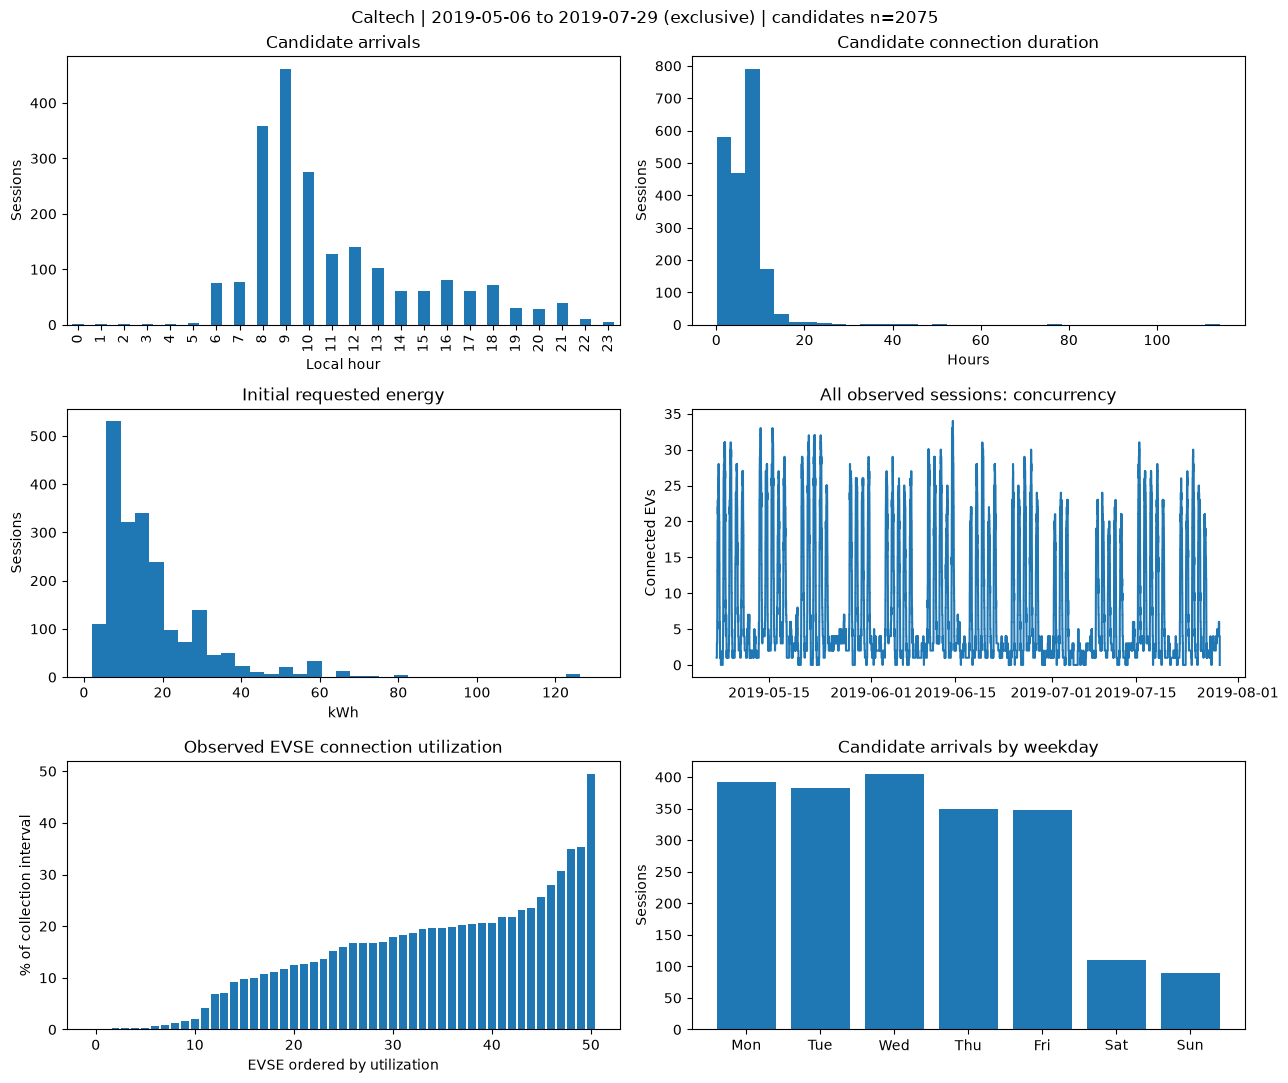

环境到达/离站事件： 4150
连接期间后续输入事件： 2335
原始分页哈希：全部一致
可重跑处理脚本：src/data_preprocessing.py
画像、字段说明、信息规则及成果哈希索引：已保存


In [13]:
from pathlib import Path
import ast
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
DATA = PROJECT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
RAW = PROJECT / "data/raw/caltech_12weeks_20261111T143402Z_9b087d"
EXTERNAL = PROJECT / "data/external"
REPORT = PROJECT / "report"
FIGURES = PROJECT / "results/figures"

for folder in [REPORT, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# 导出之前实际执行过的清洗和划分单元，不导出下载或令牌输入。
def assigned_names(code):
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return set()
    names = set()
    for node in tree.body:
        if isinstance(node, ast.Assign):
            for target in node.targets:
                names.update(
                    n.id for n in ast.walk(target)
                    if isinstance(n, ast.Name)
                )
    return names

history = list(get_ipython().history_manager.input_hist_raw)
clean_cells = [
    c for c in history
    if {"groups", "exact_duplicates", "online"}.issubset(assigned_names(c))
]
split_cells = [
    c for c in history
    if {"bounds", "ranges", "updates_by_session"}.issubset(assigned_names(c))
]
if not clean_cells or not split_cells:
    raise RuntimeError(
        "当前内核缺少清洗或划分执行历史，请反馈，不用重新下载。"
    )

old_root = (
    'PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")'
)
new_root = "PROJECT = Path(__file__).resolve().parents[1]"
script = (
    '"""Replay stage-one cleaning and chronological splits."""\n'
    "from pathlib import Path\n"
    + new_root + "\n"
    + f"SNAPSHOT = PROJECT / 'data/raw/{RAW.name}'\n\n"
    + clean_cells[-1].replace(old_root, new_root)
    + "\n\n"
    + split_cells[-1].replace(old_root, new_root)
)
compile(script, "data_preprocessing.py", "exec")
(PROJECT / "src/data_preprocessing.py").write_text(script, encoding="utf-8")

# 读取最终数据。
s = pd.read_csv(DATA / "sessions_with_split.csv", dtype="string")
truth = pd.read_csv(DATA / "environment_truth.csv", dtype="string")
u = pd.read_csv(DATA / "user_updates.csv", dtype="string")
g = pd.read_csv(DATA / "grid_checks.csv", dtype="string")

for frame, columns in [
    (s, ["connectionTime"]),
    (truth, ["disconnectTime"]),
    (u, ["modifiedAt", "requestedDeparture"]),
    (g, ["first_visible_time"]),
]:
    for column in columns:
        frame[column] = pd.to_datetime(
            frame[column], format="mixed", utc=True, errors="coerce"
        )

env = s.merge(
    truth[["sessionID", "disconnectTime"]],
    on="sessionID", validate="one_to_one",
)
assert len(env) == 2075
assert env["sessionID"].is_unique

# 环境私有事件：同一时刻先离站，再接入。
arrivals = env[["sessionID", "connectionTime"]].rename(
    columns={"connectionTime": "event_time"}
).assign(event_type="arrival", priority=1)

departures = env[["sessionID", "disconnectTime"]].rename(
    columns={"disconnectTime": "event_time"}
).assign(event_type="departure", priority=0)

events = pd.concat([arrivals, departures], ignore_index=True)
events = events.sort_values(
    ["event_time", "priority", "sessionID"], kind="stable"
)
events.to_csv(DATA / "environment_events.csv", index=False)

released = u[u["valid"].str.lower().eq("true")].merge(
    env[["sessionID", "connectionTime", "disconnectTime", "cohort", "split"]],
    on="sessionID", validate="many_to_one",
)
released = released[
    released["modifiedAt"].gt(released["connectionTime"])
    & released["modifiedAt"].lt(released["disconnectTime"])
].copy()
released["input_order"] = pd.to_numeric(released["input_order"])
released = released.sort_values(
    ["modifiedAt", "sessionID", "input_order"], kind="stable"
)
released.to_csv(DATA / "input_release_events.csv", index=False)

policy = {
    "main_at_arrival": "freeze_arrival_request_and_departure_estimate",
    "supplement_after_submission": "release_valid_inputs_at_modifiedAt",
    "equal_timestamp_order": ["departure", "arrival", "input_update"],
    "input_tie_break": "ascending_input_order_last_update_wins",
    "scheduler_must_not_read": [
        "environment_truth.csv", "environment_events.csv",
        "split_boundary_audit.csv", "grid_checks.csv",
    ],
}
(DATA / "information_policy.json").write_text(
    json.dumps(policy, ensure_ascii=False, indent=2), encoding="utf-8"
)

# 初始请求画像：主队列用到达时请求，补充队列用首次提交时请求。
initial = g[["sessionID", "first_visible_time"]].merge(
    u[u["valid"].str.lower().eq("true")],
    on="sessionID", how="inner",
)
initial = initial[
    initial["modifiedAt"].eq(initial["first_visible_time"])
].copy()
initial["input_order"] = pd.to_numeric(initial["input_order"])
initial = initial.sort_values("input_order").drop_duplicates(
    "sessionID", keep="last"
)

demand = s[["sessionID", "initial_kWhRequested"]].merge(
    initial[["sessionID", "kWhRequested"]], on="sessionID", how="left"
)
demand["energy_kWh"] = pd.to_numeric(
    demand["initial_kWhRequested"].fillna(demand["kWhRequested"]),
    errors="coerce",
)
assert demand["energy_kWh"].notna().all()

# 并发及连接利用率使用完整原始占用清单。
inventory = pd.read_csv(DATA / "evse_inventory.csv", dtype="string")
for column in ["connectionTime", "disconnectTime"]:
    inventory[column] = pd.to_datetime(
        inventory[column], format="mixed", utc=True
    )
start = pd.Timestamp("2019-05-06", tz="America/Los_Angeles").tz_convert("UTC")
end = pd.Timestamp("2019-07-29", tz="America/Los_Angeles").tz_convert("UTC")
clipped_start = inventory["connectionTime"].clip(lower=start, upper=end)
clipped_end = inventory["disconnectTime"].clip(lower=start, upper=end)

delta = pd.concat([
    pd.Series(1, index=clipped_start),
    pd.Series(-1, index=clipped_end),
]).groupby(level=0).sum().sort_index()
concurrency = delta.cumsum()
utilization = (
    (clipped_end - clipped_start).dt.total_seconds()
    .groupby(inventory["stationID"]).sum()
    / (end - start).total_seconds()
)

fig, axes = plt.subplots(3, 2, figsize=(13, 11))
local = env["connectionTime"].dt.tz_convert("America/Los_Angeles")

local.dt.hour.value_counts().reindex(
    range(24), fill_value=0
).plot.bar(ax=axes[0, 0])
axes[0, 0].set(
    title="Candidate arrivals", xlabel="Local hour", ylabel="Sessions"
)

stay = (env["disconnectTime"] - env["connectionTime"]).dt.total_seconds() / 3600
axes[0, 1].hist(stay, bins=35)
axes[0, 1].set(
    title="Candidate connection duration", xlabel="Hours", ylabel="Sessions"
)

axes[1, 0].hist(demand["energy_kWh"], bins=35)
axes[1, 0].set(
    title="Initial requested energy", xlabel="kWh", ylabel="Sessions"
)

axes[1, 1].step(
    concurrency.index.tz_convert("America/Los_Angeles"),
    concurrency.values, where="post",
)
axes[1, 1].set(
    title="All observed sessions: concurrency", ylabel="Connected EVs"
)

axes[2, 0].bar(
    range(len(utilization)), utilization.sort_values().values * 100
)
axes[2, 0].set(
    title="Observed EVSE connection utilization",
    xlabel="EVSE ordered by utilization", ylabel="% of collection interval",
)

weekday_counts = local.dt.dayofweek.value_counts().reindex(
    range(7), fill_value=0
)
axes[2, 1].bar(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday_counts
)
axes[2, 1].set(
    title="Candidate arrivals by weekday", ylabel="Sessions"
)

fig.suptitle(
    "Caltech | 2019-05-06 to 2019-07-29 (exclusive) | candidates n=2075"
)
fig.tight_layout()
fig.savefig(FIGURES / "data_profile.png", dpi=160)
plt.show()

counts = pd.crosstab(s["split"], s["cohort"]).reindex(
    ["development", "validation", "test"]
)
count_table = "\n".join("    " + line for line in counts.to_string().splitlines())

profile_text = f"""# 数据画像与阶段一记录

数据区间：洛杉矶当地 2019-05-06 至 2019-07-29，右端不含。
原始会话 2434；无可用输入排除 355；跨集合边界排除 4；
最终候选 2075。未发现重复会话或 EVSE 占用重叠。

## 队列与划分

{count_table}

严格主队列 122 条，占原始会话约 5.01%，存在信息提交选择偏差。
补充队列 1953 条，信息只能在 modifiedAt 生效后使用。
两个队列分别评价，不能将合并样本称为严格到达时信息实验。
测试集覆盖 21 天，但严格主队列仅 39 条。

主队列初始窗口不足一格 0 条、首次控制前已离站 1 条；
补充队列对应为 3 条、4 条，均保留标记。
真实离站中断时按实际分钟积分。

## 参数

采用实验 TOU、50 kW 聚合容量和连续功率，详见 assumptions.md。
三个集合电价无缺失，原网络支路约束未纳入基础聚合模型。

## 信息接口

sessions_with_split.csv 为会话输入。
input_release_events.csv 由环境按时间释放，禁止提前交给调度器。
environment_events.csv 和 environment_truth.csv 为环境私有。
严格主队列固定到达时目标，后续修改只作审计。
含修改补充实验的评价目标与下调超额规则在阶段二明确。

## 图片

results/figures/data_profile.png。
到达、停留、需求和星期分布使用 2075 条候选会话。
并发与设备连接利用率使用完整原始占用清单。
连接利用率不是实际充电利用率。
"""
(REPORT / "data_profile.md").write_text(profile_text, encoding="utf-8")

dictionary = """# 主要字段与用途

|字段|单位或含义|使用规则|
|---|---|---|
|sessionID|会话唯一编号|接入后可见|
|stationID / spaceID|原始设备编号 / 配置映射编号|固定连接|
|connectionTime|接入时间，UTC|接入后可见|
|initial_kWhRequested|到达时总请求，kWh|晚提交队列初始为空|
|initial_requestedDeparture|到达时预计离站，UTC|严格主队列使用|
|modifiedAt|输入提交时间，UTC|达到该时间才释放|
|kWhRequested|累计总目标，kWh|不是新增需求|
|requestedDeparture|预计离站，UTC|不是实际离站|
|input_order|原始输入顺序|同提交时刻后者覆盖前者|
|disconnectTime|真实离站，UTC|环境私有|
|historical_kWhDelivered|历史最终交付，kWh|仅审计|
|price_USD_per_kWh|实验电价|预先公布，按站点当地时间映射|
"""
(REPORT / "data_dictionary.md").write_text(dictionary, encoding="utf-8")

# 必要对账：原始分页哈希、事件数量。
manifest = json.loads((RAW / "manifest.json").read_text())
for page in manifest["pages"]:
    actual = hashlib.sha256((RAW / page["file"]).read_bytes()).hexdigest()
    assert actual == page["sha256"], page["file"]
assert len(events) == 2 * len(s)

files = [
    p
    for folder in [
        DATA, PROJECT / "configs", PROJECT / "src",
        EXTERNAL, REPORT, FIGURES,
    ]
    for p in folder.rglob("*")
    if p.is_file()
    and "__pycache__" not in p.parts
    and p.name != "stage1_artifact_index.csv"
]
pd.DataFrame([
    {
        "path": str(p.relative_to(PROJECT)),
        "bytes": p.stat().st_size,
        "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
    }
    for p in sorted(set(files))
]).to_csv(REPORT / "stage1_artifact_index.csv", index=False)

print("环境到达/离站事件：", len(events))
print("连接期间后续输入事件：", len(released))
print("原始分页哈希：全部一致")
print("可重跑处理脚本：src/data_preprocessing.py")
print("画像、字段说明、信息规则及成果哈希索引：已保存")

In [14]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import subprocess
import sys

PROJECT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
DATA = PROJECT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
SCRIPT = PROJECT / "src/data_preprocessing.py"

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN = PROJECT / "results/logs" / f"preprocessing_replay_{stamp}"
RUN.mkdir(parents=True, exist_ok=False)

# 这些文件由导出的清洗与划分脚本生成。
# 备份到本次日志目录，再比较重跑后的内容。
targets = [
    DATA / name for name in [
        "sessions.csv",
        "user_updates.csv",
        "environment_truth.csv",
        "exclusions.csv",
        "evse_inventory.csv",
        "evse_overlaps.csv",
        "cleaning_summary.json",
        "sessions_with_split.csv",
        "split_boundary_audit.csv",
        "grid_checks.csv",
        "grid_development.csv",
        "grid_validation.csv",
        "grid_test.csv",
    ]
] + [PROJECT / "configs/splits.yaml"]

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

before = {}
for path in targets:
    relative = path.relative_to(PROJECT)
    backup = RUN / "before" / relative
    backup.parent.mkdir(parents=True, exist_ok=True)
    content = path.read_bytes()
    backup.write_bytes(content)
    before[str(relative)] = hashlib.sha256(content).hexdigest()

print("解释器：", sys.executable)
print("独立运行：", SCRIPT, flush=True)

# 工作目录放在日志目录，避免脚本偶然依赖 Notebook 当前目录。
with (RUN / "stdout_stderr.txt").open("w", encoding="utf-8") as log:
    result = subprocess.run(
        [sys.executable, str(SCRIPT)],
        cwd=RUN,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
    )

comparison = []
for path in targets:
    relative = str(path.relative_to(PROJECT))
    after_hash = sha256(path) if path.exists() else None
    comparison.append({
        "path": relative,
        "before_sha256": before[relative],
        "after_sha256": after_hash,
        "identical": before[relative] == after_hash,
    })

passed = result.returncode == 0 and all(
    row["identical"] for row in comparison
)
report = {
    "script": str(SCRIPT.relative_to(PROJECT)),
    "script_sha256": sha256(SCRIPT),
    "python": sys.executable,
    "return_code": result.returncode,
    "passed": passed,
    "comparison": comparison,
}
(RUN / "verification.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("退出码：", result.returncode)
print("比较文件数：", len(comparison))
print("完全一致：", sum(row["identical"] for row in comparison))
print("日志目录：", RUN)

if passed:
    print("\n独立重跑通过：14 个文件与原结果完全一致。")
else:
    print("\n独立重跑未通过，请反馈下面的信息：")
    for row in comparison:
        if not row["identical"]:
            print("内容不一致：", row["path"])
    print("\n运行日志末尾：")
    log_text = (RUN / "stdout_stderr.txt").read_text(encoding="utf-8")
    print("\n".join(log_text.splitlines()[-35:]))

解释器： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/bin/python
独立运行： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/src/data_preprocessing.py
退出码： 0
比较文件数： 14
完全一致： 14
日志目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/preprocessing_replay_20261111T152835Z

独立重跑通过：14 个文件与原结果完全一致。
